# This notebook illustrates the calculation of the formation and quenching timescale for 1 massive quiescent candidates and 4 rejuvenating candidates in the sample.

In [ ]:
# Numpy 
import numpy as np

# Pandas  
import pandas as pd 

# Matplotlib packages
import matplotlib.pyplot as plt
from matplotlib import rc
from mpl_toolkits.axes_grid1 import make_axes_locatable, axes_size
from matplotlib.patches import Ellipse
%matplotlib inline
rc('axes', linewidth=2)

# Bagpipes 
import bagpipes as pipes

# Astropy packages
from astropy.wcs import WCS
from astropy.io import fits
from astropy.stats import sigma_clipped_stats, sigma_clip
import astropy.visualization as vis
from astropy.cosmology import Planck18 as cosmo
from astropy.visualization.wcsaxes import WCSAxes
from astropy.cosmology import Planck13, z_at_value
import astropy.units as u

# Photutils packages
from photutils.centroids import centroid_2dg, centroid_com, centroid_sources
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry
from photutils.background import Background2D, MedianBackground

# Remove warnings from the notebook
import warnings
warnings.filterwarnings('ignore')

# Imgutils 
from imgutils import *

# Now let's use the entire available screen width for the notebook
from IPython.display import display, HTML
display(HTML("<style>.container { width:95% !important; }</style>"))

# Define the Flat Lambda CDM model to calculate parameters like redshifts, cosmic ages 
from astropy.cosmology import FlatLambdaCDM
cosmo = FlatLambdaCDM(H0=70.0, Om0=0.3)

# Define the folder of your images
dir_images =  '/Users/quocanh1306/Downloads/'

# Define the folder to save your plots
dir_output = '/Users/quocanh1306/Desktop/Research/highredshiftgalaxies/ceers_research/Plots/'

#Define the dir of the info csv file of all galaxies in the studied sample 
dir_csv = '/Users/quocanh1306/Downloads/all_candidates_cat.csv'

#Load the catalog csv file
cat_selected = pd.read_csv(dir_csv)

#Import new/additional candidates 
dir_save_new = '/Users/quocanh1306/Downloads/new_candidates.csv'
sfh_data_new = pd.read_csv(dir_save_new)

In [ ]:
# Define the calculation functions

def nsfr_cal(lookback_time, sfr): 
    """
    This function calculates the normalized SFR (nSFR) from the SED SFH (Carnall et al., 2018)
    """

    # Convert inputs to numpy arrays for easier computation
    lookback_time = np.asarray(lookback_time)
    sfr = np.asarray(sfr)

    # Sort the arrays based on lookback time, from the earliest time to the present
    sort_indices = np.argsort(lookback_time)[::-1]
    lookback_time_sorted = lookback_time[sort_indices]
    sfr_sorted = sfr[sort_indices]
    
    # Convert lookback time from Myr to years
    time_years = lookback_time_sorted * 1e6

    # Calculate the positive time difference between each step (in years)
    # We integrate forward in time (from largest lookback time to present).
    # The interval is the time between a step and the next one in the sorted array.
    dt_intervals = time_years[:-1] - time_years[1:]
    # The cumulative mass at the very first (earliest) time step is 0.
    # We use its SFR for the first time interval, so we append a 0 for the last interval.
    dt = np.append(dt_intervals, 0)

    # Calculate the mass formed in each time interval.
    # We use the SFR at the beginning of an interval, applied over that interval's duration.
    mass_formed = sfr_sorted * dt #(Unit: solar mass)

    # Calculate the cumulative stellar mass over time
    cumulative_mass = np.cumsum(mass_formed)

    # Total mass is the last value in the cumulative mass array
    total_mass = cumulative_mass[-1]

    # Calculate the percentage of mass formed in each time interval
    mass_per = (cumulative_mass / total_mass)*100

    # Calculate the percentage of mass formed in each time interval
    ssfr = (sfr_sorted / cumulative_mass)

    ssfr_z =  np.log10(ssfr[-1])

    # Calculate t_form
    per = 50 
    t_form = np.interp(per, mass_per, lookback_time_sorted)

    # Calculate the normalized SFR (nSFR)
    nSFR = (time_years * sfr_sorted) / cumulative_mass 

    thres = 0.1 

    # A boolean array 
    is_quenched = nSFR < thres

    # Quenching should be from False -> True, so the diff at the threshold point is 1 
    transitions = np.diff(is_quenched.astype(int)) 

    # Find the index of the most recent quenching event
    quenching_indices = np.where(transitions == 1)[0]
    t_quench_array = lookback_time_sorted[quenching_indices]

    if (quenching_indices.size > 0):
        if (t_quench_array[-1] < t_form): 
            t_quench = lookback_time_sorted[quenching_indices][-1] # The most recent event
            # Quenching timescale 
            q_time = t_form - t_quench
        else:
            t_quench = None #Galaxy never quenched or was always quenched
            q_time = None

    else:
        t_quench = None #Galaxy never quenched or was always quenched
        q_time = None

   
    return lookback_time_sorted, nSFR, t_quench_array, t_quench, t_form, q_time

def quenching_time(lookback_time, sfr, spec_z):
    """
    Analyzes a star formation history to calculate cumulative stellar mass
    and the percentage of mass formed at specific lookback times.

    Args:
        lookback_time (list or np.ndarray): Array of lookback times in millions of years (Myr).
                                            The array should be sorted from most recent (0) to most distant.
        sfr (list or np.ndarray): Array of star formation rates (SFR) in solar masses per year (Msun/yr),
                                  corresponding to the lookback_time array.
        spec_z: redshift 

    Returns:
        t_quench: the quenching time (Myr)
        threshold: Value of the sSFR below which the galaxy is defined as a quiescent galaxy (unit: yr^-1)
    """

    # Convert inputs to numpy arrays for easier computation
    lookback_time = np.asarray(lookback_time)
    sfr = np.asarray(sfr)

    # Sort the arrays based on lookback time, from the earliest time to the present
    sort_indices = np.argsort(lookback_time)[::-1]
    lookback_time_sorted = lookback_time[sort_indices]
    sfr_sorted = sfr[sort_indices]

    
    # Convert lookback time from Myr to years
    time_years = lookback_time_sorted * 1e6

    # Calculate the positive time difference between each step (in years)
    # We integrate forward in time (from largest lookback time to present).
    # The interval is the time between a step and the next one in the sorted array.
    dt_intervals = time_years[:-1] - time_years[1:]
    # The cumulative mass at the very first (earliest) time step is 0.
    # We use its SFR for the first time interval, so we append a 0 for the last interval.
    dt = np.append(dt_intervals, 0)

    # Calculate the mass formed in each time interval.
    # We use the SFR at the beginning of an interval, applied over that interval's duration.
    mass_formed = sfr_sorted * dt #(Unit: solar mass)

    # Calculate the cumulative stellar mass over time
    cumulative_mass = np.cumsum(mass_formed)

    # Total mass is the last value in the cumulative mass array
    total_mass = cumulative_mass[-1]

    # Calculate the percentage of mass formed in each time interval
    mass_per = (cumulative_mass / total_mass)*100

    # Calculate the percentage of mass formed in each time interval
    ssfr = (sfr_sorted / cumulative_mass)

    ssfr_z =  np.log10(ssfr[-1])

    # Calculate t_form
    per = 50 
    t_form = np.interp(per, mass_per, lookback_time_sorted)


    # Calculate t_quench 
    t_gyr = cosmo.age(spec_z).value

    

    log_mass = np.log10(total_mass)
    slope = 0.84 - (0.026 * t_gyr)
    intercept = -(6.51 - (0.11 * t_gyr))
    log_sfr = (slope * log_mass) + intercept
    thres = log_sfr - log_mass - 0.6

    # A boolean array 
    is_quenched = ssfr < 10**thres

    # Quenching should be from False -> True, so the diff at the threshold point is 1 
    transitions = np.diff(is_quenched.astype(int)) 

    # Find the index of the most recent quenching event
    trans_indices = np.where((transitions == -1))[0]
    quenching_indices = np.where(transitions == 1)[0]
    t_quench_array_0 = lookback_time_sorted[quenching_indices]
    is_quench_after_t = t_quench_array_0 < t_form 
    t_quench_array = t_quench_array_0[is_quench_after_t]
    t_trans_array_0 = lookback_time_sorted[trans_indices]
    

    if (t_quench_array.size > 0):
        
        t_quench = t_quench_array[-1] # The most recent event
        # Quenching timescale 
        q_time = t_form - t_quench

        is_rejuvenated = t_trans_array_0 < t_quench 
        t_rejuvenation_array = t_trans_array_0[is_rejuvenated]

        if (t_rejuvenation_array.size > 0):
            t_rejuvenation =  t_rejuvenation_array[-1]
        else:
            t_rejuvenation = None 

    else:
        t_quench = None #Galaxy never quenched or was always quenched
        q_time = None
        t_rejuvenation = None 

   
    return lookback_time_sorted, ssfr_z, ssfr, t_quench_array, t_rejuvenation, t_quench, t_form, q_time, thres

def analyze_star_formation(lookback_time, sfr, milestones=None, milestones_mp=None):
    """
    Analyzes a star formation history to calculate cumulative stellar mass
    and the percentage of mass formed at specific lookback times.

    Args:
        lookback_time (list or np.ndarray): Array of lookback times in millions of years (Myr).
                                            The array should be sorted from most recent (0) to most distant.
        sfr (list or np.ndarray): Array of star formation rates (SFR) in solar masses per year (Msun/yr),
                                  corresponding to the lookback_time array.
        milestones (list, optional): A list of lookback times (in Myr) at which to calculate the
                                     percentage of mass formed. Defaults to [1000, 5000, 10000].

    Returns:
        tuple: A tuple containing:
            - np.ndarray: The original lookback_time array, sorted from past to present.
            - np.ndarray: The cumulative stellar mass in solar masses (Msun) as a function of time.
            - dict: A dictionary where keys are the milestone lookback times and values are the
                    percentage of the total mass formed by that time.
    """
    if milestones is None:
        milestones = [1000, 5000, 10000] # Default milestones: 1, 5, and 10 Gyr ago

    if milestones_mp is None:
        milestones_mp = [25, 50, 75] # Default percentage of mass formed: 25%, 50% and 75% 

    # Convert inputs to numpy arrays for easier computation
    lookback_time = np.asarray(lookback_time)
    sfr = np.asarray(sfr)

    # Sort the arrays based on lookback time, from the earliest time to the present
    sort_indices = np.argsort(lookback_time)[::-1]
    lookback_time_sorted = lookback_time[sort_indices]
    sfr_sorted = sfr[sort_indices]
    
    # Convert lookback time from Myr to years
    time_years = lookback_time_sorted * 1e6

    # Calculate the positive time difference between each step (in years)
    # We integrate forward in time (from largest lookback time to present).
    # The interval is the time between a step and the next one in the sorted array.
    dt_intervals = time_years[:-1] - time_years[1:]
    # The cumulative mass at the very first (earliest) time step is 0.
    # We use its SFR for the first time interval, so we append a 0 for the last interval.
    dt = np.append(dt_intervals, 0)


    # Calculate the mass formed in each time interval.
    # We use the SFR at the beginning of an interval, applied over that interval's duration.
    mass_formed = sfr_sorted * dt

    # Calculate the cumulative stellar mass over time
    cumulative_mass = np.cumsum(mass_formed)

    # Total mass is the last value in the cumulative mass array
    total_mass = cumulative_mass[-1]

    # Calculate the percentage of mass formed in each time interval
    mass_per = (cumulative_mass / total_mass)*100

    
    if total_mass == 0:
        print("Warning: Total mass formed is zero. Cannot calculate percentages.")
        return lookback_time_sorted, cumulative_mass, {m: 0 for m in milestones}

    # Calculate the percentage of mass formed at specified milestones
    mass_percentages = {}
    lbt_percentages = {}
    for milestone in milestones:
        # Find the cumulative mass at the milestone time using interpolation
        # We use np.interp to find the cumulative mass at the exact milestone lookback time
        # Note: interp needs x-coordinates to be increasing, so we reverse the arrays for it.
        mass_at_milestone = np.interp(milestone, lookback_time_sorted[::-1], cumulative_mass[::-1])
        percentage = (mass_at_milestone / total_mass) * 100
        mass_percentages[milestone] = percentage
    
    for per in milestones_mp:
        # Find the lookback time at the mass percentage using interpolation
        # We use np.interp to find the cumulative mass at the exact milestone lookback time
        # Note: interp needs x-coordinates to be increasing, so we reverse the arrays for it.
        lbt_at_milestones_mp = np.interp(per, mass_per, lookback_time_sorted)
        lbt_percentages[per] = lbt_at_milestones_mp

    return lookback_time_sorted, cumulative_mass, mass_per, total_mass, lbt_percentages


In [ ]:
# Define a loading function --> the SED fitting requires a loading function
def load_data(ID):
    dir_images =  '/Users/quocanh1306/Downloads/'
    dir_phot = dir_images + f"phot_results_{ID}.csv"
    phot_data = pd.read_csv(dir_phot)
    phot_array = [] 
    err_array = []
    for i in range(len(Filters) - 0):
        i = i + 0
        phot_array.append(phot_data.iloc[i][1])
        err_array.append(phot_data.iloc[i+len(Filters)][1])
    
    photometry = np.c_[phot_array, err_array]

    return photometry 

photometry = load_data(2)

print(photometry)

[[0.1812316 0.0095377]
 [0.2249229 0.0085707]
 [0.46579   0.0100718]
 [0.7909444 0.0086251]
 [1.0609891 0.0040468]
 [1.0794335 0.003572 ]
 [1.3129327 0.0086534]
 [1.4050945 0.0066128]]


### Plot the SFH for the 1 massive QG and 4 rejuvenating candidates in the sample 


Results loaded from pipes/posterior/cont_qanh_Mar18_try_1/65.h5

Fitting not performed as results have already been loaded from pipes/posterior/cont_qanh_Mar18_try_1/65.h5. To start over delete this file or change run.

29.17975035948856
9.000000000003599
Quenching timescale:  20.17975035948496


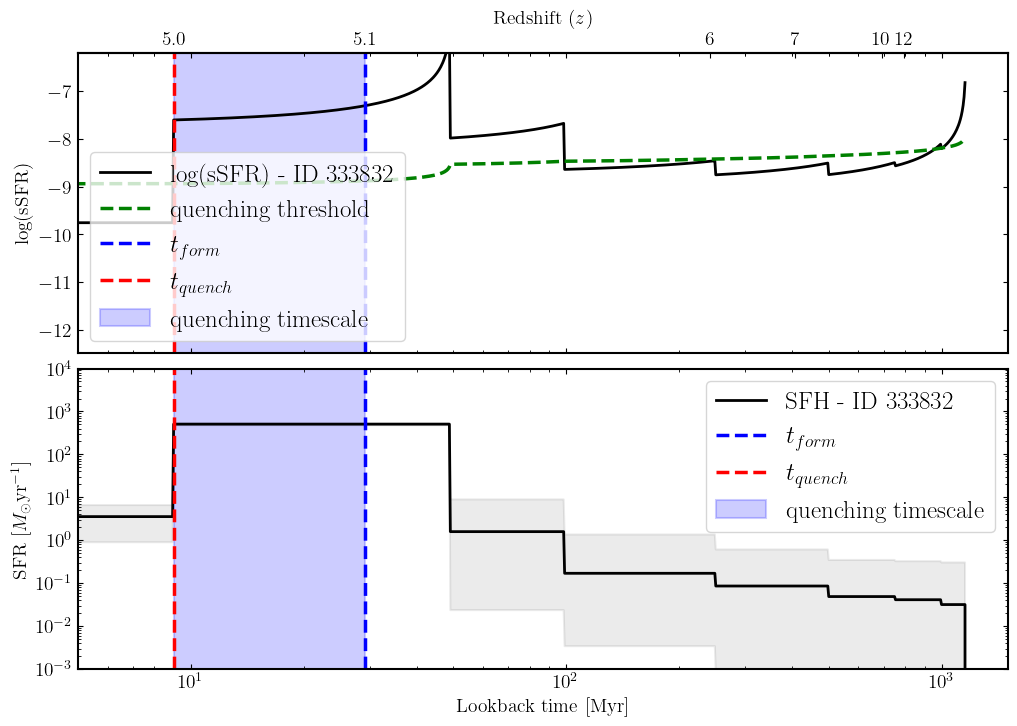

In [ ]:
# Obtain the SFH plots for a massive QG in our sample 
list_new_ids = [65]

#Arrays 

SFH_models = ['delayed', 'dblplaw', 'continuity']
SFH_runs = ["dtau_qanh_Mar18", "dpl_qanh_Mar18", "cont_qanh_Mar18_try_1"]
SFH_colors = ['blue', 'red', 'green']


SFH_cmh_results = {}

for i in range(len(list_new_ids)): 
    gal_id = list_new_ids[i] 
    gal_id_2 = list_new_ids[i] 

    if gal_id < 77:
            Name = cat_selected["ID"].iloc[gal_id]
            gal_z = cat_selected["spec-z"].iloc[gal_id]
        
        else:
            Name = sfh_data_new["ID"].iloc[gal_id_2 - 77]
            gal_z = sfh_data_new["spec-z"].iloc[gal_id_2 - 77]
    
    cosmo = FlatLambdaCDM(H0=70.0, Om0=0.3)
    age_univ = cosmo.age(gal_z).value


    Filters = ['f090w', 'f115w', 'f150w', 'f200w', 'f277w', 'f356w', 'f410m', 'f444w']
    filter_list_jwst = ['filters/jwst_nircam_f090w.txt', 'filters/jwst_nircam_f115w.txt', 'filters/jwst_nircam_f150w.txt', 'filters/jwst_nircam_f200w.txt', 
        'filters/jwst_nircam_f277w.txt', 'filters/jwst_nircam_f356w.txt', 'filters/jwst_nircam_f410m.txt', 'filters/jwst_nircam_f444w.txt']


    load_data(gal_id)

    fit_delayed = {}                                  
    fit_delayed["age"] = (0.001, age_univ)        # Age in units of Gyr         
    fit_delayed["age_prior"] = "log_10"
    fit_delayed["tau"] = (0.001, 30.0)            # in units of Gyr
    fit_delayed["tau_prior"] = "log_10"            
    fit_delayed["massformed"] = (4., 12.)               # vary log_10(M*/M_solar)
    fit_delayed["metallicity"] = (0.01, 2.5)            # in units of solar metallicity
    fit_delayed["metallicity_prior"] = "log_10"

    fit_dblplaw = {}                        
    fit_dblplaw["tau"] = (0., 15.)                # Vary the time of peak star-formation between
                                          # the Big Bang at 0 Gyr and 15 Gyr later. In 
                                          # practice the code automatically stops this
                                          # exceeding the age of the universe at the 
                                          # observed redshift.
            
    fit_dblplaw["alpha"] = (0.01, 1000.)          # Vary the falling power law slope from 0.01 to 1000.
    fit_dblplaw["beta"] = (0.01, 1000.)           # Vary the rising power law slope from 0.01 to 1000.
    fit_dblplaw["alpha_prior"] = "log_10"         # Impose a prior which is uniform in log_10 of the 
    fit_dblplaw["beta_prior"] = "log_10"          # parameter between the limits which have been set 
                                          # above as in Carnall et al. (2017).
    fit_dblplaw["massformed"] = (4., 12.)
    fit_dblplaw["metallicity"] = (0.01, 2.5)

    fit_dust = {}                                 # Dust component
    fit_dust["type"] = "Calzetti"                 # Define the shape of the attenuation curve
    fit_dust["Av"] = (0., 3.0)                    # Vary Av between 0 and 3 magnitudes
    fit_dust["eta"] = 1.0

    fit_nebular = {}                              # Nebula component  
    fit_nebular["logU"] = (-3.0, -1.0)            # Define the ionization parameter 


    continuity = {}                               # Non-parametric component using continuity priors 
    continuity["massformed"] = (4., 12.)
    continuity["metallicity"] = (0.01, 2.5)
    continuity["metallicity_prior"] = "log_10"
    continuity["bin_edges"] = [0., 10., 50., 100., 250., 500., 750., 1000., age_univ*1000] #age_univ is the cosmological age at observed z
    #continuity["bin_edges"] = [0., 10., 50., 100., 250., 500., 1000., 2000.]

    for j in range(1, len(continuity["bin_edges"])-1):
        continuity["dsfr" + str(j)] = (-10., 10.)
        continuity["dsfr" + str(j) + "_prior"] = "student_t"
        #continuity["dsfr" + str(i) + "_prior_scale"] = 0.3  # Defaults to this value as in Leja19, but can be set
        #continuity["dsfr" + str(i) + "_prior_df"] = 2       # Defaults to this value as in Leja19, but can be set

    SFH_dictionaries = [fit_delayed, fit_dblplaw, continuity]

    fig, (f1, f2) = plt.subplots(2,1, figsize=(12,8))
    plt.subplots_adjust(wspace=0.15, hspace=0.05) # Slightly wider spacing for text legibility
    # 1. Use twinx() to create a truly independent secondary y-axis
    #f2 = f1.twinx()
    f2.set_yscale('log')
    f1.set_xscale('log')
    f2.set_xscale('log')

    plt.rc('text', usetex=True)
    plt.rc('font', family='serif')
    f2.set_xlabel('Lookback time [Myr]', fontsize=14)
    #plt.xlabel('Age/Gyr', fontsize=14)
    f1.set_ylabel(r'log(sSFR)', fontsize=14)
    f2.set_ylabel(r'SFR [$M_{\odot}\rm{yr}^{-1}$]', fontsize=14)
    f1.set_xlim(5, 1500.0)
    f2.set_xlim(5, 1500.0)
    f1.set_ylim(-12.5, -6.2)
    f2.set_ylim(0.001, 10000.0)
    f1.tick_params(labelbottom=False)


    for k in range(1): 
        k = 2
        SFH_dict = SFH_dictionaries[k]
        SFH_run = SFH_runs[k]
        SFH_model = SFH_models[k]
        color = SFH_colors[k]
        fit_instructions_2 = {}                                     # fit instructions dictionary
        fit_instructions_2["redshift"] = gal_z
        fit_instructions_2["dust"] = fit_dust
        fit_instructions_2["nebular"] = fit_nebular
        fit_instructions_2[SFH_model] = continuity
        my_galaxy = pipes.galaxy(str(gal_id), load_data, phot_units='mujy', spectrum_exists=False, photometry_exists=True, filt_list=filter_list_jwst)
        fit = pipes.fit(my_galaxy, fit_instructions_2, run=SFH_run)
        fit.fit(verbose=False, n_live = 1000)
        max_age = max(fit.posterior.sfh.ages*10**-9)
        post_sfh_t = max_age - fit.posterior.sfh.ages*10**-9
        post_sfh_lbt = fit.posterior.sfh.ages*10**-9
        post_sfh_age = age_univ - (post_sfh_lbt - 0.001) 
        mask = post_sfh_age > -0.1
        post_sfh_sfr = np.percentile(fit.posterior.samples["sfh"], (16, 50, 84), axis=0).T
        sfh_plot = f2.plot(post_sfh_lbt*1e+3-1.0, post_sfh_sfr[:, 1], color='black', zorder=1, label = f'SFH - ID {Name}')
        sfh_scatter = f2.fill_between(post_sfh_lbt*1e+3-1.0, post_sfh_sfr[:, 0], post_sfh_sfr[:, 2], color='black', alpha=0.08, zorder=0, lw=1.5)
       
        
        #plt.plot(post_sfh_age[mask], post_sfh_sfr[:, 1][mask],color='black', alpha = 0.1, zorder=1)

        lookback_time_sorted, ssfr_z, ssfr, t_quench_array, t_rej, t_quench, t_form, q_time, threshold = quenching_time(post_sfh_lbt*1e+3 - 1, post_sfh_sfr[:, 1], gal_z)
        ssfr_plot = f1.plot(post_sfh_lbt*1e+3-1.0, np.log10(ssfr[::-1]), color='black', zorder=1, label = f'log(sSFR) - ID {Name}')
        ssfr_thres_plot = f1.plot(post_sfh_lbt*1e+3-1.0, threshold[::-1], color='green', linestyle='--', linewidth=2.5, label = f'quenching threshold')
       

        if t_quench == None: 
            print("NOTHING")
        else:
            f1.axvline(x=t_form, color='blue', linestyle='--', linewidth=2.5, label = r'$t_{form}$')
            f2.axvline(x=t_form, color='blue', linestyle='--', linewidth=2.5, label = r'$t_{form}$')
            print(t_form)
            print(t_quench)
            #print(t_rej)
            f1.axvline(x=t_quench, color='red' , linestyle='--', linewidth=2.5, label = r'$t_{quench}$')
            f2.axvline(x=t_quench, color='red' , linestyle='--', linewidth=2.5, label = r'$t_{quench}$')
    
            #plt.axvline(x=t_rej, color='green' , linestyle='--', linewidth=2.5, label = 't_rejuvenation')
            rejuvenile_scatter = f1.fill_between(np.array([t_quench, t_form]), -12.5, -6, color='blue', alpha=0.2, zorder=0, lw=1.5, label = 'quenching timescale')
            rejuvenile_scatter_1 = f2.fill_between(np.array([t_quench, t_form]), 0.0001, 100000, color='blue', alpha=0.2, zorder=0, lw=1.5, label = 'quenching timescale')

            print("Quenching timescale: ", t_form - t_quench)
            #print("Rejuvenation timescale: ", t_quench - t_rej)
            z_quench =  z_at_value(cosmo.age, (age_univ * 1e+3 - t_quench) * u.Myr).value 
            z_form = z_at_value(cosmo.age, (age_univ * 1e+3 - t_form) * u.Myr).value 
            #z_trans = z_at_value(cosmo.age, (age_univ * 1e+3 - t_rej) * u.Myr).value 
            sec_ticks_z = [round(z_quench,1), round(z_form,1), 5, 6, 7, 10, 12]
            sec_ticks_z1 = [z_quench, z_form, 5, 6, 7, 10, 12]
            ages_1 = cosmo.age(sec_ticks_z1).value
            sec_ticks_lbt_myr = (age_univ - ages_1)* 1e+3
        
            #sec_ticks_age_gyr = ages

            # 3. Create the secondary axis and apply the ticks
            secax = f1.secondary_xaxis('top')
            secax.set_xlabel('Redshift ($z$)', fontsize=14, labelpad=5)
            secax.set_xticks(sec_ticks_lbt_myr)
            secax.set_xticklabels(sec_ticks_z)
        
       

            f1.legend()
            f2.legend()

    



Results loaded from pipes/posterior/cont_qanh_Mar18/24.h5

Fitting not performed as results have already been loaded from pipes/posterior/cont_qanh_Mar18/24.h5. To start over delete this file or change run.

371.9497809447886
248.74683891562938
8.942600739533136
Quenching timescale:  123.2029420291592
Rejuvenation timescale:  239.80423817609625

Results loaded from pipes/posterior/cont_qanh_Mar18/27.h5

Fitting not performed as results have already been loaded from pipes/posterior/cont_qanh_Mar18/27.h5. To start over delete this file or change run.

438.7233260406231
98.42600739536715
8.942600739533136
Quenching timescale:  340.2973186452559
Rejuvenation timescale:  89.48340665583402

Results loaded from pipes/posterior/cont_qanh_Mar18/89.h5

Fitting not performed as results have already been loaded from pipes/posterior/cont_qanh_Mar18/89.h5. To start over delete this file or change run.

297.78113896117037
98.42600739536715
8.942600739533136
Quenching timescale:  199.35513156580322
R

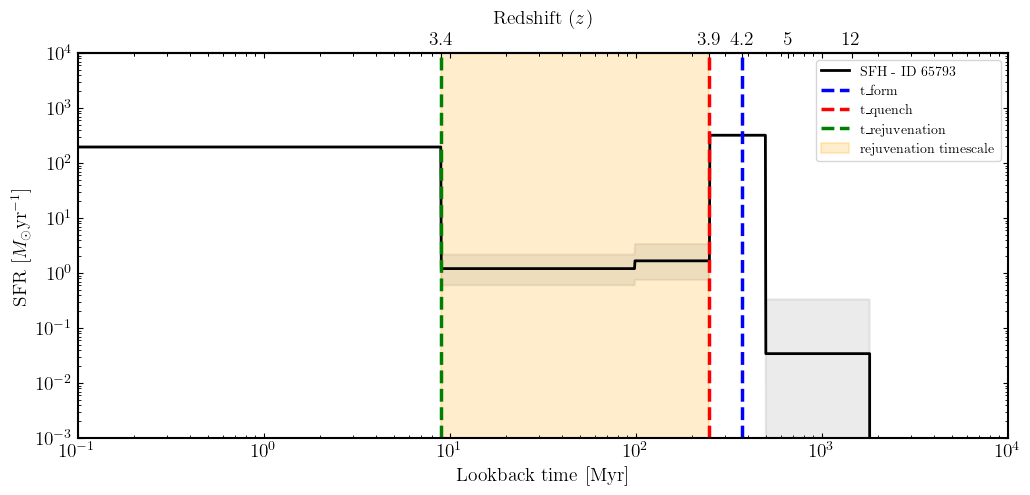

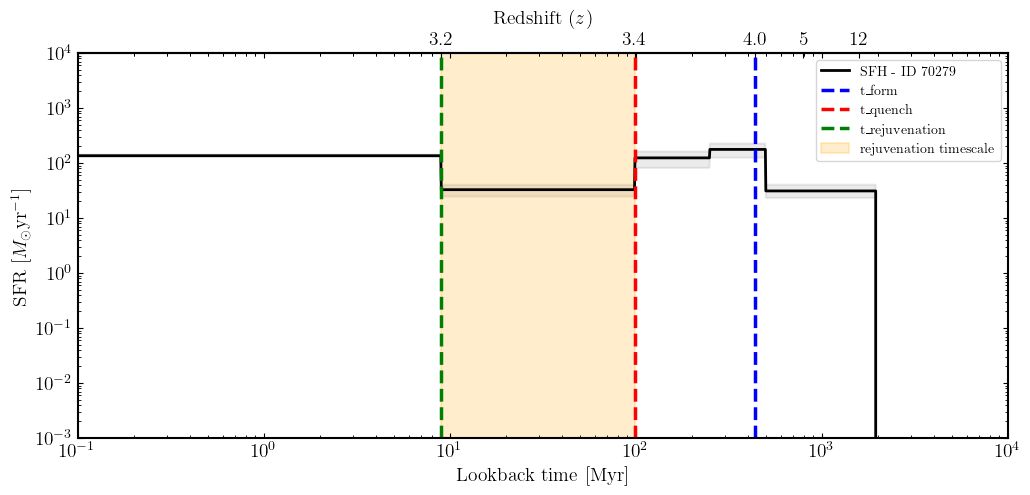

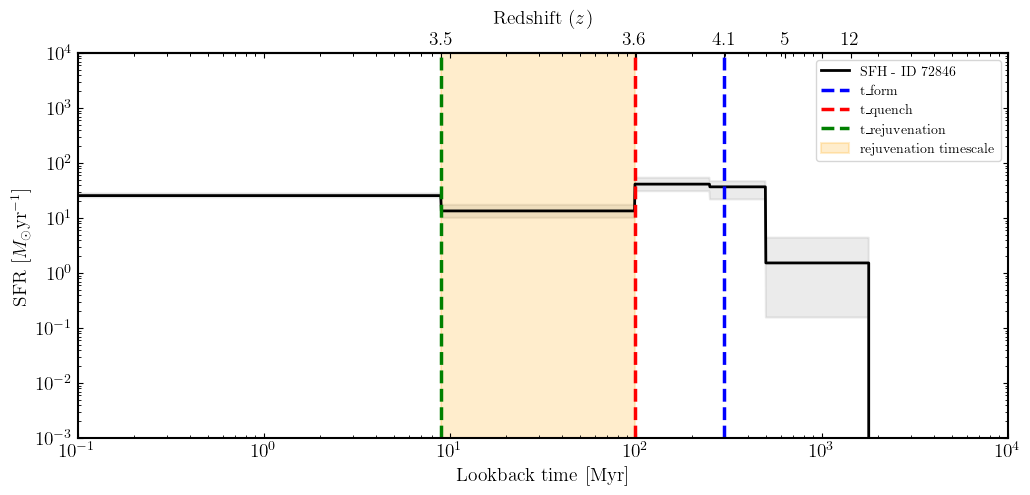

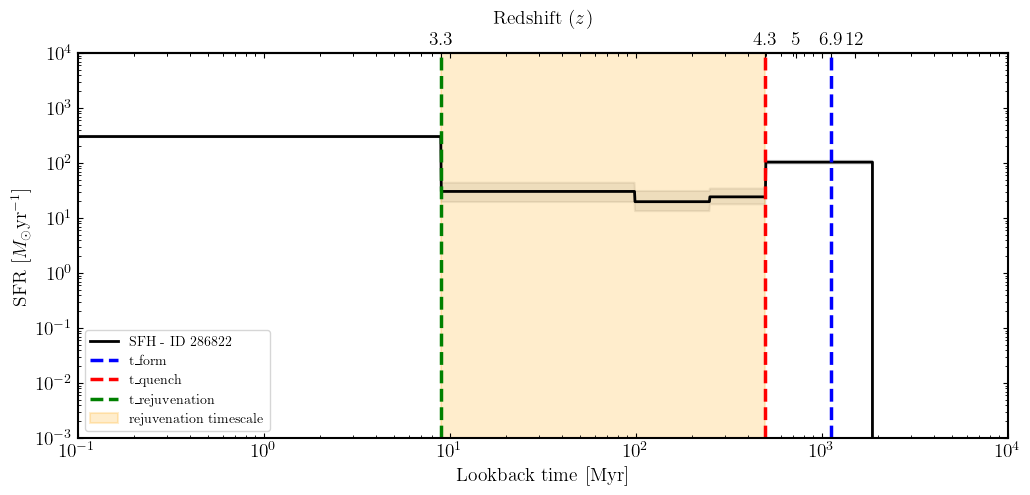

In [ ]:
# Obtain the SFH plots 
list_new_ids = [24, 27, 89, 100]

#Import new data
dir_save_new = '/Users/quocanh1306/Downloads/new_candidates.csv'
sfh_data_new = pd.read_csv(dir_save_new)

# SFH Arrays 
SFH_models = ['delayed', 'dblplaw', 'continuity']
SFH_runs = ["dtau_qanh_Mar18", "dpl_qanh_Mar18", "cont_qanh_Mar18"]
SFH_colors = ['blue', 'red', 'green']
SFH_cmh_results = {}

for i in range(len(list_new_ids)): 
    gal_id = list_new_ids[i] 
    gal_id_2 = list_new_ids[i] 

    if gal_id < 77:
        Name = cat_selected["ID"].iloc[gal_id]
        gal_z = cat_selected["spec-z"].iloc[gal_id]
    
    else:
        Name = sfh_data_new["ID"].iloc[gal_id_2 - 77]
        gal_z = sfh_data_new["spec-z"].iloc[gal_id_2 - 77]
    
    cosmo = FlatLambdaCDM(H0=70.0, Om0=0.3)
    age_univ = cosmo.age(gal_z).value

    Filters = ['f090w', 'f115w', 'f150w', 'f200w', 'f277w', 'f356w', 'f410m', 'f444w']
    filter_list_jwst = ['filters/jwst_nircam_f090w.txt', 'filters/jwst_nircam_f115w.txt', 'filters/jwst_nircam_f150w.txt', 'filters/jwst_nircam_f200w.txt', 
                         'filters/jwst_nircam_f277w.txt', 'filters/jwst_nircam_f356w.txt', 'filters/jwst_nircam_f410m.txt', 'filters/jwst_nircam_f444w.txt']

    load_data(gal_id)

    fit_delayed = {}                                  
    fit_delayed["age"] = (0.001, age_univ)        # Age in units of Gyr         
    fit_delayed["age_prior"] = "log_10"
    fit_delayed["tau"] = (0.001, 30.0)            # in units of Gyr
    fit_delayed["tau_prior"] = "log_10"            
    fit_delayed["massformed"] = (4., 12.)               # vary log_10(M*/M_solar)
    fit_delayed["metallicity"] = (0.01, 2.5)            # in units of solar metallicity
    fit_delayed["metallicity_prior"] = "log_10"

    fit_dblplaw = {}                        
    fit_dblplaw["tau"] = (0., 15.)                # Vary the time of peak star-formation between
                                          # the Big Bang at 0 Gyr and 15 Gyr later. In 
                                          # practice the code automatically stops this
                                          # exceeding the age of the universe at the 
                                          # observed redshift.
            
    fit_dblplaw["alpha"] = (0.01, 1000.)          # Vary the falling power law slope from 0.01 to 1000.
    fit_dblplaw["beta"] = (0.01, 1000.)           # Vary the rising power law slope from 0.01 to 1000.
    fit_dblplaw["alpha_prior"] = "log_10"         # Impose a prior which is uniform in log_10 of the 
    fit_dblplaw["beta_prior"] = "log_10"          # parameter between the limits which have been set 
                                          # above as in Carnall et al. (2017).
    fit_dblplaw["massformed"] = (4., 12.)
    fit_dblplaw["metallicity"] = (0.01, 2.5)

    fit_dust = {}                                 # Dust component
    fit_dust["type"] = "Calzetti"                 # Define the shape of the attenuation curve
    fit_dust["Av"] = (0., 3.0)                     # Vary Av between 0 and 2 magnitudes
    fit_dust["eta"] = 1.0

    fit_nebular = {}                      
    fit_nebular["logU"] = (-3.0, -1.0) 


    continuity = {}
    continuity["massformed"] = (4., 12.)
    continuity["metallicity"] = (0.01, 2.5)
    continuity["metallicity_prior"] = "log_10"
    #continuity["bin_edges"] = [0., 10., 100., 250., 500., 1000., 2000.]
    continuity["bin_edges"] = [0., 10., 100., 250., 500., age_univ*1000]

    for j in range(1, len(continuity["bin_edges"])-1):
        continuity["dsfr" + str(j)] = (-10., 10.)
        continuity["dsfr" + str(j) + "_prior"] = "student_t"
        #continuity["dsfr" + str(i) + "_prior_scale"] = 0.3  # Defaults to this value as in Leja19, but can be set
        #continuity["dsfr" + str(i) + "_prior_df"] = 2       # Defaults to this value as in Leja19, but can be set

    SFH_dictionaries = [fit_delayed, fit_dblplaw, continuity]

    fig, f1 = plt.subplots(figsize=(12,5))
    f1.set_yscale('log')
    f1.set_xscale('log')
    plt.rc('text', usetex=True)
    plt.rc('font', family='serif')
    plt.xlabel('Lookback time [Myr]', fontsize=14)
    f1.set_ylabel(r'SFR [$M_{\odot}\rm{yr}^{-1}$]', fontsize=14)
    plt.xlim(0.1, 10000.0)
    f1.set_ylim(0.001, 10000.0)


    for k in range(1): 
        k = 2
        SFH_dict = SFH_dictionaries[k]
        SFH_run = SFH_runs[k]
        SFH_model = SFH_models[k]
        color = SFH_colors[k]
        fit_instructions_2 = {}
        fit_instructions_2["redshift"] = gal_z
        fit_instructions_2["dust"] = fit_dust
        fit_instructions_2["nebular"] = fit_nebular
        fit_instructions_2[SFH_model] = SFH_dict 
        my_galaxy = pipes.galaxy(str(gal_id), load_data, phot_units='mujy', spectrum_exists=False, photometry_exists=True, filt_list=filter_list_jwst)
        fit = pipes.fit(my_galaxy, fit_instructions_2, run=SFH_run)
        fit.fit(verbose=False, n_live = 1000)
        max_age = max(fit.posterior.sfh.ages*10**-9)
        post_sfh_t = max_age - fit.posterior.sfh.ages*10**-9
        post_sfh_lbt = fit.posterior.sfh.ages*10**-9
        post_sfh_age = age_univ - (post_sfh_lbt - 0.001) 
        mask = post_sfh_age > -0.1
        post_sfh_sfr = np.percentile(fit.posterior.samples["sfh"], (16, 50, 84), axis=0).T
        sfh_plot = f1.plot(post_sfh_lbt*1e+3-1.0, post_sfh_sfr[:, 1], color='black', zorder=1, label = f'SFH - ID {Name}')
        sfh_scatter = f1.fill_between(post_sfh_lbt*1e+3-1.0, post_sfh_sfr[:, 0], post_sfh_sfr[:, 2], color='black', alpha=0.08, zorder=0, lw=1.5)
        #plt.plot(post_sfh_age[mask], post_sfh_sfr[:, 1][mask],color='black', alpha = 0.1, zorder=1)

        lookback_time_sorted, ssfr_z, ssfr, t_quench_array, t_rej, t_quench, t_form, q_time, threshold = quenching_time(post_sfh_lbt*1e+3 - 1, post_sfh_sfr[:, 1], gal_z)

        if t_rej == None: 
            print("NOTHING")
        else:
            plt.axvline(x=t_form, color='blue', linestyle='--', linewidth=2.5, label = 't_form')
            print(t_form)
            print(t_quench)
            print(t_rej)
            plt.axvline(x=t_quench, color='red' , linestyle='--', linewidth=2.5, label = 't_quench')
            plt.axvline(x=t_rej, color='green' , linestyle='--', linewidth=2.5, label = 't_rejuvenation')
            rejuvenile_scatter = plt.fill_between(np.array([t_rej, t_quench]), 0.001, 100000.0, color='orange', alpha=0.2, zorder=0, lw=1.5, label = 'rejuvenation timescale')

            print("Quenching timescale: ", t_form - t_quench)
            print("Rejuvenation timescale: ", t_quench - t_rej)
            z_quench =  z_at_value(cosmo.age, (age_univ * 1e+3 - t_quench) * u.Myr).value 
            z_form = z_at_value(cosmo.age, (age_univ * 1e+3 - t_form) * u.Myr).value 
            z_trans = z_at_value(cosmo.age, (age_univ * 1e+3 - t_rej) * u.Myr).value 
            sec_ticks_z = [round(z_trans,1), round(z_quench,1), round(z_form,1), 5, 12]
            sec_ticks_z1 = [z_trans, z_quench, z_form, 5, 12]
            ages_1 = cosmo.age(sec_ticks_z1).value
            sec_ticks_lbt_myr = (age_univ - ages_1)* 1e+3


            # 3. Create the secondary axis and apply the ticks
            secax = f1.secondary_xaxis('top')
            secax.set_xlabel('Redshift ($z$)', fontsize=14, labelpad=5)
            secax.set_xticks(sec_ticks_lbt_myr)
            secax.set_xticklabels(sec_ticks_z)
            plt.legend()

    


### Check the specific-SFR history of the 4 rejuvenating candidates


Results loaded from pipes/posterior/cont_qanh_Mar18/24.h5

Fitting not performed as results have already been loaded from pipes/posterior/cont_qanh_Mar18/24.h5. To start over delete this file or change run.



python(98766) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(98768) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.



Results loaded from pipes/posterior/cont_qanh_Mar18/25.h5

Fitting not performed as results have already been loaded from pipes/posterior/cont_qanh_Mar18/25.h5. To start over delete this file or change run.



python(98769) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(98771) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.



Results loaded from pipes/posterior/cont_qanh_Mar18/27.h5

Fitting not performed as results have already been loaded from pipes/posterior/cont_qanh_Mar18/27.h5. To start over delete this file or change run.



python(98772) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(98773) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.



Results loaded from pipes/posterior/cont_qanh_Mar18/100.h5

Fitting not performed as results have already been loaded from pipes/posterior/cont_qanh_Mar18/100.h5. To start over delete this file or change run.



python(98774) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(98775) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(98777) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(98778) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(98779) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(98780) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


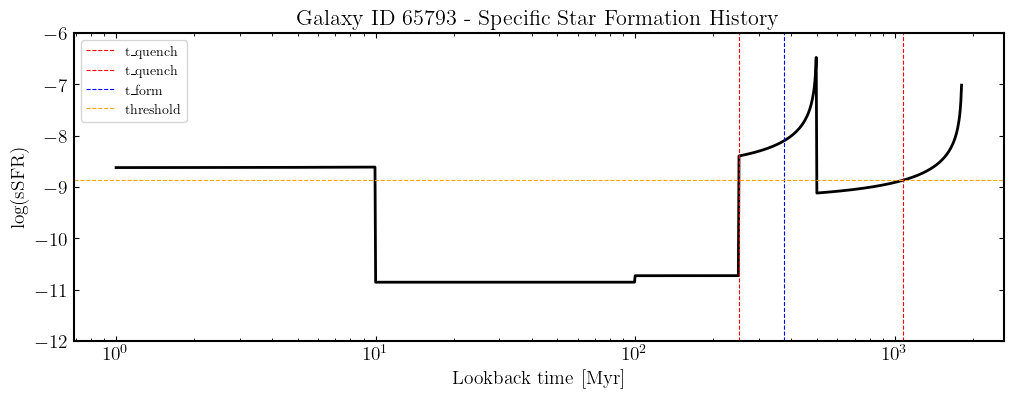

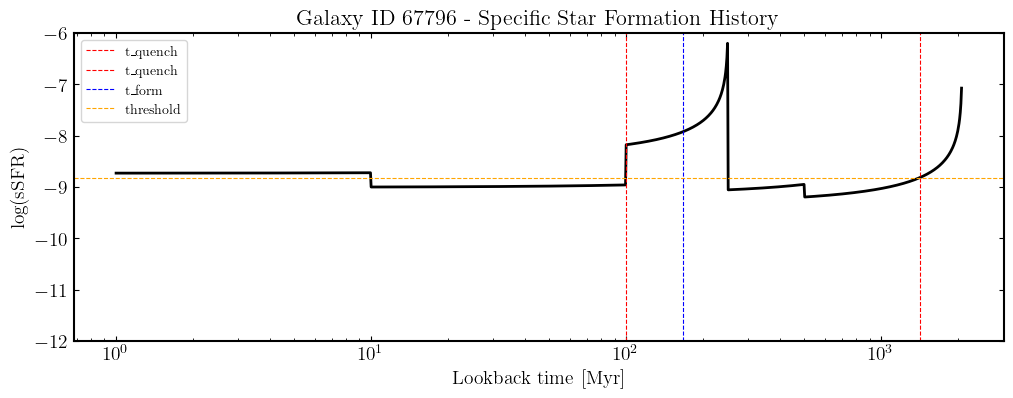

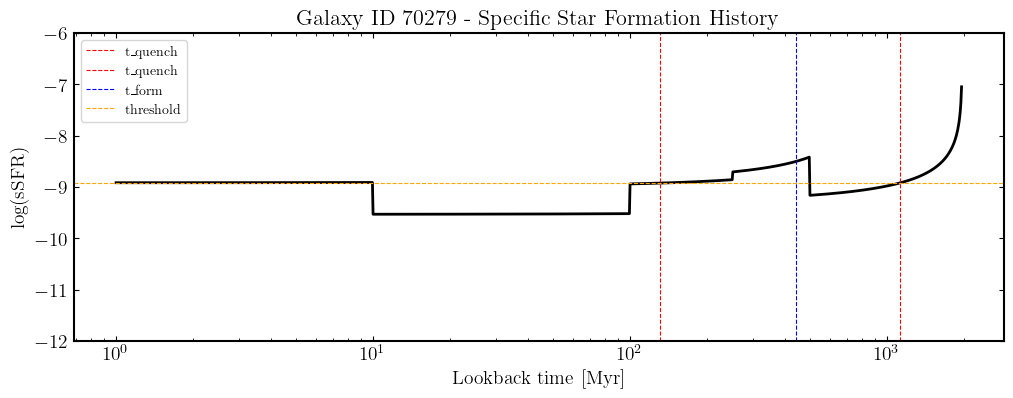

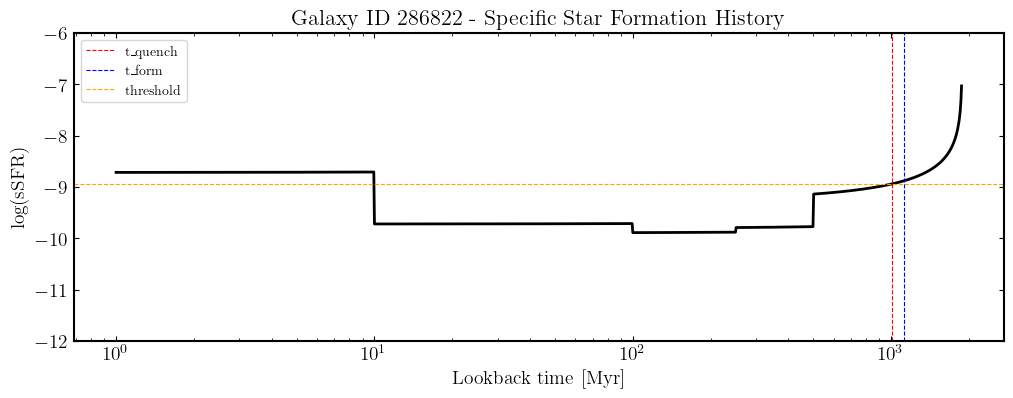

In [ ]:
# Obtain the SSFR history check plots 
list_new_ids = [24, 25, 27, 100]

#Arrays 
SFH_models = ['delayed', 'dblplaw', 'continuity']
SFH_runs = ["dtau_qanh_Mar18", "dpl_qanh_Mar18", "cont_qanh_Mar18"]
model_cont = [2]
SFH_colors = ['blue', 'red', 'green']

for i in range(len(list_new_ids)): 
    gal_id = list_new_ids[i] 
    gal_id_2 = list_new_ids[i] 

    if gal_id < 77:
        Name = ceers_selected["ID"].iloc[gal_id]
        gal_z = ceers_selected["spec-z"].iloc[gal_id]
    
    else:
        Name = sfh_data_new["ID"].iloc[gal_id_2 - 77]
        gal_z = sfh_data_new["spec-z"].iloc[gal_id_2 - 77]
    
    cosmo = FlatLambdaCDM(H0=70.0, Om0=0.3)
    age_univ = cosmo.age(gal_z).value

    if gal_id == 103:
        Filters = ['f090w', 'f115w', 'f150w', 'f200w', 'f277w', 'f356w', 'f444w']
        filter_list_jwst = ['filters/jwst_nircam_f090w.txt', 'filters/jwst_nircam_f115w.txt', 'filters/jwst_nircam_f150w.txt', 'filters/jwst_nircam_f200w.txt', 
        'filters/jwst_nircam_f277w.txt', 'filters/jwst_nircam_f356w.txt', 'filters/jwst_nircam_f444w.txt']
    
    elif gal_id == 3:
        Filters = ['f090w', 'f277w', 'f356w', 'f410m', 'f444w']
        filter_list_jwst = ['filters/jwst_nircam_f090w.txt', 'filters/jwst_nircam_f277w.txt', 'filters/jwst_nircam_f356w.txt', 'filters/jwst_nircam_f410m.txt', 'filters/jwst_nircam_f444w.txt']

    elif gal_id == 50: 
        Filters = ['f090w', 'f115w', 'f150w', 'f200w', 'f277w', 'f444w']
        filter_list_jwst = ['filters/jwst_nircam_f090w.txt', 'filters/jwst_nircam_f115w.txt', 'filters/jwst_nircam_f150w.txt', 'filters/jwst_nircam_f200w.txt',  'filters/jwst_nircam_f277w.txt', 'filters/jwst_nircam_f444w.txt']

    elif gal_id == 12: 
        Filters = ['f115w', 'f150w', 'f200w', 'f277w', 'f356w', 'f410m', 'f444w']
        filter_list_jwst = [ 'filters/jwst_nircam_f115w.txt', 'filters/jwst_nircam_f150w.txt', 'filters/jwst_nircam_f200w.txt', 
        'filters/jwst_nircam_f277w.txt', 'filters/jwst_nircam_f356w.txt', 'filters/jwst_nircam_f410m.txt', 'filters/jwst_nircam_f444w.txt']

    else:
        Filters = ['f090w', 'f115w', 'f150w', 'f200w', 'f277w', 'f356w', 'f410m', 'f444w']
        filter_list_jwst = ['filters/jwst_nircam_f090w.txt', 'filters/jwst_nircam_f115w.txt', 'filters/jwst_nircam_f150w.txt', 'filters/jwst_nircam_f200w.txt', 
        'filters/jwst_nircam_f277w.txt', 'filters/jwst_nircam_f356w.txt', 'filters/jwst_nircam_f410m.txt', 'filters/jwst_nircam_f444w.txt']


    load_data(gal_id)

    fit_delayed = {}                                  
    fit_delayed["age"] = (0.001, age_univ)        # Age in units of Gyr         
    fit_delayed["age_prior"] = "log_10"
    fit_delayed["tau"] = (0.001, 30.0)            # in units of Gyr
    fit_delayed["tau_prior"] = "log_10"            
    fit_delayed["massformed"] = (4., 12.)               # vary log_10(M*/M_solar)
    fit_delayed["metallicity"] = (0.01, 2.5)            # in units of solar metallicity
    fit_delayed["metallicity_prior"] = "log_10"

    fit_dblplaw = {}                        
    fit_dblplaw["tau"] = (0., 15.)                # Vary the time of peak star-formation between
                                          # the Big Bang at 0 Gyr and 15 Gyr later. In 
                                          # practice the code automatically stops this
                                          # exceeding the age of the universe at the 
                                          # observed redshift.
            
    fit_dblplaw["alpha"] = (0.01, 1000.)          # Vary the falling power law slope from 0.01 to 1000.
    fit_dblplaw["beta"] = (0.01, 1000.)           # Vary the rising power law slope from 0.01 to 1000.
    fit_dblplaw["alpha_prior"] = "log_10"         # Impose a prior which is uniform in log_10 of the 
    fit_dblplaw["beta_prior"] = "log_10"          # parameter between the limits which have been set 
                                          # above as in Carnall et al. (2017).
    fit_dblplaw["massformed"] = (4., 12.)
    fit_dblplaw["metallicity"] = (0.01, 2.5)

    fit_dust = {}                                 # Dust component
    fit_dust["type"] = "Calzetti"                 # Define the shape of the attenuation curve
    fit_dust["Av"] = (0., 3.0)                     # Vary Av between 0 and 2 magnitudes
    fit_dust["eta"] = 1.0

    fit_nebular = {}                      
    fit_nebular["logU"] = (-3.0, -1.0) 


    continuity = {}
    continuity["massformed"] = (4., 12.)
    continuity["metallicity"] = (0.01, 2.5)
    continuity["metallicity_prior"] = "log_10"
    #continuity["bin_edges"] = [0., 10., 100., 250., 500., 1000., 2000.]
    continuity["bin_edges"] = [0., 10., 100., 250., 500., age_univ*1000]

    for j in range(1, len(continuity["bin_edges"])-1):
        continuity["dsfr" + str(j)] = (-10., 10.)
        continuity["dsfr" + str(j) + "_prior"] = "student_t"
        #continuity["dsfr" + str(i) + "_prior_scale"] = 0.3  # Defaults to this value as in Leja19, but can be set
        #continuity["dsfr" + str(i) + "_prior_df"] = 2       # Defaults to this value as in Leja19, but can be set

    SFH_dictionaries = [fit_delayed, fit_dblplaw, continuity]



    for k in model_cont: 
        SFH_dict = SFH_dictionaries[k]
        SFH_run = SFH_runs[k]
        SFH_model = SFH_models[k]
        color = SFH_colors[k]
        fit_instructions_2 = {}
        fit_instructions_2["redshift"] = gal_z
        fit_instructions_2["dust"] = fit_dust
        fit_instructions_2["nebular"] = fit_nebular
        fit_instructions_2[SFH_model] = SFH_dict 
        my_galaxy = pipes.galaxy(str(gal_id), load_data, phot_units='mujy', spectrum_exists=False, photometry_exists=True, filt_list=filter_list_jwst)
        fit = pipes.fit(my_galaxy, fit_instructions_2, run=SFH_run)
        fit.fit(verbose=False, n_live = 1000)
        max_age = max(fit.posterior.sfh.ages*10**-9)
        post_sfh_t = max_age - fit.posterior.sfh.ages*10**-9
        post_sfh_lbt = fit.posterior.sfh.ages*10**-9
        post_sfh_sfr = np.percentile(fit.posterior.samples["sfh"], (16, 50, 84), axis=0).T
        sfh_samples = fit.posterior.samples["sfh"]
        idx1 = np.where(post_sfh_sfr[:, 1]>0.0)[0]

        lookback_time_sorted, ssfr_z, ssfr, t_quench_array, t_quench, t_form, q_time, threshold = quenching_time(post_sfh_lbt[idx1]*1e+3, post_sfh_sfr[idx1, 1], gal_z)
        fig = plt.figure(figsize=(12,4))
        f1 = plt.subplot()
        #f1.set_yscale('log')
        f1.set_xscale('log')
        plt.rc('text', usetex=True)
        plt.rc('font', family='serif')
        plt.xlabel('Lookback time [Myr]', fontsize=14)
        plt.ylabel('log(sSFR)', fontsize=14)
        #plt.xlim(0.001, 10000.0)
        plt.ylim(-12, -6)
        plt.plot(lookback_time_sorted, np.log10(ssfr), color='black', zorder=1)
        plt.title(f'Galaxy ID {Name} - Specific Star Formation History', fontsize = 16)
        #save_path = f'/Users/quocanh1306/Downloads/SED_18Mar_CONT/SFH2_cont_{Name}.png'
        fig.savefig(save_path, bbox_inches='tight', dpi=300, facecolor='white')
        for z in range(len(t_quench_array)):
             plt.axvline(x=t_quench_array[z], color='red' , linestyle='--', linewidth=0.8, label = 't_quench')
        plt.axvline(x=t_form, color='blue', linestyle='--', linewidth=0.8, label = 't_form')
        plt.axhline(y=threshold, color='orange', linestyle='--', linewidth=0.8, label = 'threshold')    
    
        plt.legend()




### Calculate Quenching and formation timescale for 4 rejuvenating candidates 

In [ ]:
#Create the great loop 
#List of IDs 
from IPython.display import display, Math

list_new_ids = [24, 27, 89, 100]

SFH_models = ['delayed tau', 'dblplaw', 'continuity']
SFH_runs = ["dtau_qanh_Mar18", "dpl_qanh_Mar18", "cont_qanh_Mar18"]
SFH_dictionaries = [fit_delayed, fit_dblplaw, continuity]
SFH_colors = ['blue', 'red', 'green']
qt_50_0 = []
qt_50_1 = []
qt_50_2 = [] 
t_q_dtau_0 = []
t_q_dtau_1 = [] 
t_q_dtau_2 = []
t_q_dpl_0 = []
t_q_dpl_1 = []
t_q_dpl_2 = []
t_q_cont_0 = []
t_q_cont_1 = []
t_q_cont_2 = []
z_q_dtau_0 = []
z_q_dtau_1 = [] 
z_q_dtau_2 = []
z_q_dpl_0 = []
z_q_dpl_1 = []
z_q_dpl_2 = []
z_q_cont_0 = []
z_q_cont_1 = []
z_q_cont_2 = []
total_mass_cont_0 = [] 
total_mass_cont_1 = [] 
total_mass_cont_2 = [] 
total_mass_dtau_0 = [] 
total_mass_dtau_1 = [] 
total_mass_dtau_2 = [] 
total_mass_dpl_0 = [] 
total_mass_dpl_1 = [] 
total_mass_dpl_2 = [] 

t_f_dtau_0 = []
t_f_dtau_1 = [] 
t_f_dtau_2 = []
t_f_dpl_0 = []
t_f_dpl_1 = []
t_f_dpl_2 = []
t_f_cont_0 = []
t_f_cont_1 = []
t_f_cont_2 = []
z_f_dtau_0 = []
z_f_dtau_1 = [] 
z_f_dtau_2 = []
z_f_dpl_0 = []
z_f_dpl_1 = []
z_f_dpl_2 = []
z_f_cont_0 = []
z_f_cont_1 = []
z_f_cont_2 = []

for i in range(len(list_new_ids)): 
    gal_id = list_new_ids[i] 
    gal_id_2 = list_new_ids[i] 

    if gal_id < 77:
        Name = ceers_selected["ID"].iloc[gal_id]
        gal_z = ceers_selected["spec-z"].iloc[gal_id]
    
    else:
        Name = sfh_data_new["ID"].iloc[gal_id_2 - 77]
        gal_z = sfh_data_new["spec-z"].iloc[gal_id_2 - 77]
    
    cosmo = FlatLambdaCDM(H0=70.0, Om0=0.3)
    age_univ = cosmo.age(gal_z).value

    if gal_id == 103:
        Filters = ['f090w', 'f115w', 'f150w', 'f200w', 'f277w', 'f356w', 'f444w']
        filter_list_jwst = ['filters/jwst_nircam_f090w.txt', 'filters/jwst_nircam_f115w.txt', 'filters/jwst_nircam_f150w.txt', 'filters/jwst_nircam_f200w.txt', 
        'filters/jwst_nircam_f277w.txt', 'filters/jwst_nircam_f356w.txt', 'filters/jwst_nircam_f444w.txt']

    elif gal_id == 3:
        filter_list_jwst = ['filters/jwst_nircam_f090w.txt', 'filters/jwst_nircam_f277w.txt', 'filters/jwst_nircam_f356w.txt', 'filters/jwst_nircam_f410m.txt', 'filters/jwst_nircam_f444w.txt']
        Filters = ['f090w', 'f277w', 'f356w', 'f410m', 'f444w']

    elif gal_id == 50: 
        filter_list_jwst = ['filters/jwst_nircam_f090w.txt', 'filters/jwst_nircam_f115w.txt', 'filters/jwst_nircam_f150w.txt', 'filters/jwst_nircam_f200w.txt',  'filters/jwst_nircam_f277w.txt', 'filters/jwst_nircam_f444w.txt']
        Filters = ['f090w', 'f115w', 'f150w', 'f200w', 'f277w', 'f444w']

    elif gal_id == 12: 
        Filters = ['f115w', 'f150w', 'f200w', 'f277w', 'f356w', 'f410m', 'f444w']
        filter_list_jwst = [ 'filters/jwst_nircam_f115w.txt', 'filters/jwst_nircam_f150w.txt', 'filters/jwst_nircam_f200w.txt', 
        'filters/jwst_nircam_f277w.txt', 'filters/jwst_nircam_f356w.txt', 'filters/jwst_nircam_f410m.txt', 'filters/jwst_nircam_f444w.txt']
        
    else:
        filter_list_jwst = ['filters/jwst_nircam_f090w.txt', 'filters/jwst_nircam_f115w.txt', 'filters/jwst_nircam_f150w.txt', 'filters/jwst_nircam_f200w.txt', 
        'filters/jwst_nircam_f277w.txt', 'filters/jwst_nircam_f356w.txt', 'filters/jwst_nircam_f410m.txt', 'filters/jwst_nircam_f444w.txt']
        Filters = ['f090w', 'f115w', 'f150w', 'f200w', 'f277w', 'f356w', 'f410m', 'f444w']
    
    load_data(gal_id)
        
    for k in range(3):
        SFH_model = SFH_models[k]
        SFH_run = SFH_runs[k]
        SFH_dict = SFH_dictionaries[k]
        color = SFH_colors[k]
        fit_instructions_1 = {}
        fit_instructions_1["redshift"] = gal_z
        fit_instructions_1["dust"] = fit_dust
        fit_instructions_1["nebular"] = fit_nebular
        fit_instructions_1[SFH_model] = SFH_dict 
        my_galaxy = pipes.galaxy(str(gal_id), load_data, phot_units='mujy', spectrum_exists=False, photometry_exists=True, filt_list=filter_list_jwst)
        fit = pipes.fit(my_galaxy, fit_instructions_1, run=SFH_run)
        fit.fit(verbose=False, n_live = 1000)
        max_age = max(fit.posterior.sfh.ages*10**-9)
        post_sfh_t = max_age - fit.posterior.sfh.ages*10**-9
        post_sfh_lbt = fit.posterior.sfh.ages*10**-9
        sfh_samples = fit.posterior.samples["sfh"]
        post_sfh_sfr = np.percentile(fit.posterior.samples["sfh"], (16, 50, 84), axis=0).T

        mass_per = []
        t_form = [] 
        t_quench = [] 
        quenching_ts= [] 
        total_mass = [] 

        #idx_0 = np.where(post_sfh_sfr[:, 1]>0.0)[0]
        for j in range(sfh_samples.shape[0]):
            sfr_sample = sfh_samples[j, :]
            lbt_sorted, _, mass_percentages, tot_mass, lbt_percentages = analyze_star_formation(post_sfh_lbt*1e3, sfr_sample, milestones_mp=[25,50,75])
            lbt_sorted, ssfr_z, ssfr, t_q_array, t_trans, t_q, t_f, q_t, threshold = quenching_time_1(post_sfh_lbt*1e3-1, sfr_sample, gal_z)
            t_form.append(t_f)
            t_quench.append(t_q)
            mass_per.append(mass_percentages/100)   
            quenching_ts.append(q_t)
            total_mass.append(np.log10(tot_mass))
        
              

        t_quench_clean = np.array(t_quench, dtype=float)
        t_form_clean = np.array(t_form, dtype=float)
        quenching_timescale_clean = np.array(quenching_ts, dtype=float)
        total_mass_clean = np.array(total_mass, dtype=float)

        t_quench_results = np.nanpercentile(t_quench_clean, [16,50,84], axis = 0).T
        z_quench_results = z_at_value(cosmo.age, (age_univ*1e+3 - t_quench_results) * u.Myr).value
        t_form_results = np.nanpercentile(t_form_clean, [16,50,84], axis = 0).T
        z_form_results = z_at_value(cosmo.age, (age_univ*1e+3 - t_form_results) * u.Myr).value
        tot_mass_results = np.nanpercentile(total_mass_clean, [16,50,84], axis = 0).T
        mass_per_results =  np.nanpercentile(mass_per, [16,50,84], axis = 0).T
    
        quenching_timescale =  np.nanpercentile(quenching_timescale_clean, [16,50,84], axis = 0).T
        if k == 1:
            qt_50_1.append(quenching_timescale[1])
            t_q_dpl_0.append(t_quench_results[0])
            t_q_dpl_1.append(t_quench_results[1])
            t_q_dpl_2.append(t_quench_results[2])
            t_f_dpl_0.append(t_form_results[0])
            t_f_dpl_1.append(t_form_results[1])
            t_f_dpl_2.append(t_form_results[2])
            z_q_dpl_0.append(z_quench_results[0])
            z_q_dpl_1.append(z_quench_results[1])
            z_q_dpl_2.append(z_quench_results[2])
            z_f_dpl_0.append(z_form_results[0])
            z_f_dpl_1.append(z_form_results[1])
            z_f_dpl_2.append(z_form_results[2])
            total_mass_dpl_0.append(tot_mass_results[0])
            total_mass_dpl_1.append(tot_mass_results[1])
            total_mass_dpl_2.append(tot_mass_results[2])
          
        if k == 0: 
            qt_50_0.append(quenching_timescale[1])
            t_q_dtau_0.append(t_quench_results[0])
            t_q_dtau_1.append(t_quench_results[1])
            t_q_dtau_2.append(t_quench_results[2])
            t_f_dtau_0.append(t_form_results[0])
            t_f_dtau_1.append(t_form_results[1])
            t_f_dtau_2.append(t_form_results[2])
            z_q_dtau_0.append(z_quench_results[0])
            z_q_dtau_1.append(z_quench_results[1])
            z_q_dtau_2.append(z_quench_results[2])
            z_f_dtau_0.append(z_form_results[0])
            z_f_dtau_1.append(z_form_results[1])
            z_f_dtau_2.append(z_form_results[2])
            total_mass_dtau_0.append(tot_mass_results[0])
            total_mass_dtau_1.append(tot_mass_results[1])
            total_mass_dtau_2.append(tot_mass_results[2])
          

        if k == 2:
            qt_50_2.append(quenching_timescale[1])
            t_q_cont_0.append(t_quench_results[0])
            t_q_cont_1.append(t_quench_results[1])
            t_q_cont_2.append(t_quench_results[2])
            t_f_cont_0.append(t_form_results[0])
            t_f_cont_1.append(t_form_results[1])
            t_f_cont_2.append(t_form_results[2])
            z_q_cont_0.append(z_quench_results[0])
            z_q_cont_1.append(z_quench_results[1])
            z_q_cont_2.append(z_quench_results[2])
            z_f_cont_0.append(z_form_results[0])
            z_f_cont_1.append(z_form_results[1])
            z_f_cont_2.append(z_form_results[2])
            total_mass_cont_0.append(tot_mass_results[0])
            total_mass_cont_1.append(tot_mass_results[1])
            total_mass_cont_2.append(tot_mass_results[2])
    

        txt0 = f'Galaxy ID: {gal_id} - {SFH_model}'
        display(Math(txt0))

        '''

        q1 = np.diff(t_quench_results)
        txt1 = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
        txt1 = txt1.format(t_quench_results[1], q1[0], q1[1], r't_{quench}[Myr]')
        display(Math(txt1))

        q2 = np.diff(t_form_results)
        txt2 = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
        txt2 = txt2.format(t_form_results[1], q2[0], q2[1], r't_{form}[Myr]')
        display(Math(txt2))

        q3 = np.diff(quenching_timescale)
        txt3 = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
        txt3 = txt3.format(quenching_timescale[1], q3[0], q3[1], r'quenching timescale [Myr]')
        display(Math(txt3))
        '''

        q4 = np.diff(z_quench_results)
        txt4 = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
        txt4 = txt4.format(z_quench_results[1], q4[0], q4[1], r'z_{quench}')
        display(Math(txt4))


        q5 = np.diff(z_form_results)
        txt5 = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
        txt5 = txt5.format(z_form_results[1], q5[0], q5[1], r'z_{form}')
        display(Math(txt5))


        q6 = np.diff(tot_mass_results)
        txt6 = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
        txt6 = txt6.format(tot_mass_results[1], q6[0], q6[1], r'total mass [Solar Mass]')
        display(Math(txt6))

    
    print(f"Running galaxy {gal_id}")








Results loaded from pipes/posterior/dtau_qanh_Mar18/24.h5

Fitting not performed as results have already been loaded from pipes/posterior/dtau_qanh_Mar18/24.h5. To start over delete this file or change run.



<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

...

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Running galaxy 100
